# Experiment 1: base model comparison

## Overview

**Purpose:** train five base models under the same conditions, compare them, and pick the best ones to tune
in the next experiment.

| Item | Setup |
|---|---|
| Data | 7 recordings, one gesture each, 8 armband channels |
| Preprocessing | `PREPRO.py`: cleaning, windows, split (same folder as this notebook) |
| Models | RNN, LSTM, CNN, CNN-RNN, CNN-LSTM, default settings (no tuning) |
| Fair comparison | same data, windows, training settings and 3 seeds for every model |
| Results | test accuracy, macro F1, size, speed, plus a simple LDA baseline |

### Steps
1. Load and clean the recordings
2. Cut windows, split by time (60 / 20 / 20), balance, normalise
3. Put the data into PyTorch
4. Build the five models and check them
5. Train each model with 3 seeds
6. Test once and compare
7. Save the models

All settings are in the **Settings** cell.

### Results (150 ms window, 3 seeds, test set)

| Model | Accuracy | ± std | Macro F1 | Parameters | Model time (ms) |
|---|---|---|---|---|---|
| RNN | 65.8% | 5.0% | 0.620 | 5,191 | 0.50 |
| LSTM | 76.8% | 1.0% | 0.743 | 19,399 | 0.74 |
| CNN | 77.9% | 0.0% | 0.747 | 38,151 | 1.64 |
| CNN-RNN | 80.0% | 1.1% | 0.774 | 20,583 | 0.93 |
| **CNN-LSTM** | **81.0%** | 0.1% | **0.783** | 45,543 | 1.19 |
| LDA baseline | 61.9% | – | 0.599 | – | – |

- **Total delay:** about 151 ms for every model (window + model time).
- **Ablation:** LDA on signal strength alone (RMS) reaches 58.3%, and on a single sample 17.5%, so the deep
  models gain about 23 points from more than signal strength.
- **Weakest gestures:** radial and ulnar, for all models.

The larger window size, the higher model's accuracy in return of speed. The range 150 - 300 ms is preferred to stay close to recommended range of semi-realtime application.

### Conclusion

CNN, LSTM and CNN-LSTM are selected for tuning.
- **CNN-LSTM:** best accuracy and macro F1, very stable across seeds (±0.1%).
- **LSTM and CNN:** kept as single-part baselines (memory only, patterns only), so the tuned hybrid can be
  compared against each part. The CNN is also oversized for a 9-sample window, so tuning can shrink it.
- **RNN-based models excluded:** the plain RNN is the weakest and least stable (65.8% ± 5.0%), because its
  memory fades over the window (vanishing gradient). CNN-RNN is close to CNN-LSTM (80.0% vs 81.0%), but
  CNN-LSTM is kept as the stronger memory variant, since the LSTM's gates fix the fading-memory problem.


In [4]:
import time
import importlib
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score, f1_score, classification_report, ConfusionMatrixDisplay
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis

import torch
import torch.nn as nn
import torch.nn.functional as F

import PREPRO as pp
importlib.reload(pp)          # picks up any edits to PREPRO.py without restarting the kernel

<module 'PREPRO' from 'd:\\Study\\SC dir\\Capstone Project\\New folder\\Capstone\\Capstone\\Process\\PREPRO.py'>

## Settings

| Group | Settings | Meaning |
|---|---|---|
| Data | `DATA_FOLDER`, `CHANNELS`, `GESTURES` | where the files are, signal columns, gestures |
| Signal | `SAMPLE_RATE`, `PREP` | readings per second; cleaning and filter settings |
| Windows | `WINDOW_MS`, `STEP` | window length (the delay) and gap between windows |
| Split | `VAL_FRAC`, `TEST_FRAC`, `MAX_GAP_MS` | end part of each recording kept for validation and test |
| Balance | `BALANCE_TRAIN`, `DATA_SEED` | equal training windows per gesture; fixed data seed |
| Training | `BATCH_SIZE`, `EPOCHS`, `LEARNING_RATE`, `SEEDS` | same for every model; one run per seed |

In [ ]:
# ---------- data ----------
DATA_FOLDER = "Data"
CHANNELS = [f"V{i+1}" for i in range(8)]
GESTURES = {"fist": 1, "flexion": 2, "extension": 3, "radial": 4, "ulnar": 5, "rest": 6, "table": 7}

# ---------- signal (passed to pp.preprocess) ----------
SAMPLE_RATE = 60                 # Hz per channel - compare with the measured rate printed in Step 1
PREP = dict(
    sample_rate=SAMPLE_RATE,
    resample=False,              # True: put rows on an even 1000/SAMPLE_RATE ms grid using Time
    outlier_z=3.0,               # drop rows beyond this many std devs; None = keep all rows
    zero_centre=True,
    notch_hz=None,               # e.g. 50 for mains hum; None = off (must be below SAMPLE_RATE / 2)
    low_hz=1,                    # band-pass lower edge; None = no high-pass
    high_hz=8,                   # band-pass upper edge; None = no low-pass (must be below SAMPLE_RATE / 2)
    filter_order=4,
    causal=True,                 # True: filters only look at the past, as in live use
    per_file=True,               # True: outliers and filters per recording (False = old behaviour)
)

# ---------- windows and split (passed to pp.make_datasets) ----------
WINDOW_MS = 150
WINDOW_SIZE = SAMPLE_RATE * WINDOW_MS // 1000      # samples per window
STEP = 4                                           # samples between window starts, it's about ~53%, step = 2 for ~75%, step = 1 for ~90% overlap
SPLIT_BY = "chrono"                                # each recording: train, then validation, then test
VAL_FRAC, TEST_FRAC = 0.2, 0.2
MAX_GAP_MS = None
BALANCE_TRAIN = True
DATA_SEED = 0

# ---------- training ----------
BATCH_SIZE = 64
EPOCHS = 20
LEARNING_RATE = 0.001
SEEDS = [0, 1, 2]                                  # model seeds: starting weights, batch order, dropout

print(f"window: {WINDOW_MS} ms = {WINDOW_SIZE} samples at {SAMPLE_RATE} Hz, step {STEP}")

window: 150 ms = 9 samples at 60 Hz, step 4


## Step 1: load and clean the recordings

`pp.preprocess` reads every file, removes outlier rows, zero-centres each channel and applies the 1–8 Hz filter.
The `Time` column is kept. Check the printed rate against `SAMPLE_RATE`.

In [6]:
PREP_RAW_TIME = {**PREP, "resample": False}
data = pp.preprocess(DATA_FOLDER, channels=CHANNELS, **PREP_RAW_TIME)


loaded 7 files, 41709 rows
recorded timing per file (gaps between rows, ms):
        gesture  rows  length (s)  rate (Hz)  short <=10 ms (%)  pauses  longest pause (s)  duplicates
file                                                                                                  
01         fist  8678       269.5       53.4               41.7      89                6.0           0
02      flexion  5098       201.5       52.5               36.7      79               10.3           1
03    extension  5485       225.2       52.7               36.4      73               44.1           0
04       radial  4334       163.3       52.9               37.3      68               31.4           0
05        ulnar  3816       138.5       54.5               38.8      56                8.1           0
06         rest  6328       119.1       53.2               37.8       2                0.1           1
07        table  7970       155.6       51.2               34.8       0                0.1         

## Step 2: windows, split, balance and normalise

`pp.make_datasets` cuts each recording into windows of `WINDOW_SIZE` samples, one every `STEP` samples.
Each recording is split by time: first 60% train, next 20% validation, last 20% test.
Windows crossing a split are dropped. Training gestures are capped at the median count, and every channel is
normalised with training data only.

In [7]:
d = pp.make_datasets(data, WINDOW_SIZE, STEP, channels=CHANNELS, gestures=GESTURES,
                     val_frac=VAL_FRAC, test_frac=TEST_FRAC, max_gap_ms=MAX_GAP_MS,
                     balance_train=BALANCE_TRAIN, data_seed=DATA_SEED)

X_train, y_train = d["X_train"], d["y_train"]
X_val,   y_val   = d["X_val"],   d["y_val"]
X_test,  y_test  = d["X_test"],  d["y_test"]
test_file        = d["test_file"]          # recording each test window came from
GESTURE_NAMES    = d["gesture_names"]
N_CLASSES        = d["n_classes"]
channel_mean, channel_std = d["channel_mean"], d["channel_std"]

                windows  train  val  test  dropped
file gesture                                      
01   fist          1930   1157  384   385        4
02   flexion       1124    674  223   223        4
03   extension     1229    737  244   244        4
04   radial         960    575  190   191        4
05   ulnar          859    515  170   170        4
06   rest          1454    871  289   290        4
07   table         1812   1086  361   361        4 

windows: 9 samples, step 4; train 4712, val 1861, test 1864; samples shared between splits: 0
capped each training gesture at 737 windows:
  fist          1157 ->   737
  flexion        674 ->   674
  extension      737 ->   737
  radial         575 ->   575
  ulnar          515 ->   515
  rest           871 ->   737
  table         1086 ->   737


## Step 3: put the data into PyTorch

In [8]:
train_data = torch.utils.data.TensorDataset(torch.tensor(X_train), torch.tensor(y_train))
val_data   = torch.utils.data.TensorDataset(torch.tensor(X_val),   torch.tensor(y_val))
test_data  = torch.utils.data.TensorDataset(torch.tensor(X_test),  torch.tensor(y_test))

train_loader = torch.utils.data.DataLoader(train_data, batch_size=BATCH_SIZE, shuffle=True)
val_loader   = torch.utils.data.DataLoader(val_data,   batch_size=BATCH_SIZE)
test_loader  = torch.utils.data.DataLoader(test_data,  batch_size=BATCH_SIZE)

batch_x, batch_y = next(iter(train_loader))
print("one batch of windows:", tuple(batch_x.shape), "(batch, time steps, channels)")
print("one batch of labels: ", tuple(batch_y.shape),
      f"values {int(batch_y.min())}..{int(batch_y.max())}")

one batch of windows: (64, 9, 8) (batch, time steps, channels)
one batch of labels:  (64,) values 0..6


## Step 4: the five models

All models take a window `[batch, WINDOW_SIZE, 8]` and return one score per gesture.

| Model | How it reads the window |
|---|---|
| RNN | step by step, simple memory |
| LSTM | step by step, gated memory that fades less |
| CNN | sliding filters find short patterns, no memory |
| CNN-RNN | CNN patterns, then an RNN reads them in order |
| CNN-LSTM | CNN patterns, then an LSTM reads them in order |

- `all_steps(x)`: output at every time step.
- `forward(x)`: last step only, turned into gesture scores.
- Padding goes on the left only, so no model uses future samples.

### 4a. RNN

![RNN Example](Images/rnn_unrolled_beginner.png) 

#### Definition
A network with memory. It reads the window one step at a time, in order, and keeps a running summary of
everything seen so far, like reading a sentence word by word while keeping the gist in mind.

#### Mechanics
1. **Read one step:** the 8 electrode values at one moment.
2. **Combine with memory:** `memory = tanh(W1 · reading + W2 · old memory)`.
3. **Pass it on:** the new memory goes to the next step.
4. **Decide:** after the last step, the memory summarises the window; a linear layer gives one score per gesture.

The same weights are reused at every step.

**Weakness:** the memory fades. Older steps get diluted, so long sequences are hard. LSTM and GRU fix this with gates.

#### Pros and cons
- **Good at:** data where order matters (text, speech, sensor streams).
- **Slow:** steps run one after another, not all at once like a CNN.
- **Hard to train:** forgets the distant past and is sensitive to its settings.

#### Layers
A second layer reads the first layer's memories and can combine short patterns into longer ones.
Rule of thumb: 1–2 layers; deeper RNNs are hard to train.

#### Justification of the setup
- **8 inputs per step, `WINDOW_SIZE` steps:** each step sees all 8 electrodes at once.
- **Plain RNN, 1 layer:** the simplest memory model, the baseline the others are compared with.
- **Memory size 64:** mid-range; 5,191 parameters in total, suitable for one person's data.
- **Last time step only:** it has read the whole window.
- **Dropout 0.3:** reduces memorising.
- **7 outputs, linear layer:** one score per gesture; softmax at use gives the confidence (ML-F-05, ML-F-06).
- **`all_steps` method:** output at every step, used by the causality check.

In [10]:
class RNNModel(nn.Module):
    """
    What it does:
        Classify one window with a plain RNN (memory only).

    Steps:
        1. RNN reads the 8 channel values at every time step and updates its memory.
        2. Keep the output at the last time step.
        3. Dropout, then a linear layer gives one score per gesture.
    """
    def __init__(self, n_channels=8, n_classes=6):
        super().__init__()
        self.rnn = nn.RNN(input_size=n_channels, hidden_size=64, batch_first=True)
        self.dropout = nn.Dropout(0.3)
        self.fc = nn.Linear(64, n_classes)

    def all_steps(self, x):                 # x: [batch, 50, 8]
        out, _ = self.rnn(x)
        return out                          # [batch, 50, 64]

    def forward(self, x):
        last_step = self.all_steps(x)[:, -1, :]
        return self.fc(self.dropout(last_step))

### 4b. LSTM

![LSTM Example](Images/lstm_cell_beginner.png)
 
#### Definition
An RNN with a better memory. It reads the window one step at a time, but keeps two memories: a long-term
memory (cell state) and a short-term memory (hidden state). Gates decide what to keep, what to add and
what to output.

#### Mechanics
1. **Read one step:** the 8 electrode values plus the previous short-term memory.
2. **Forget gate:** decides which parts of the long-term memory to erase (0 = erase, 1 = keep).
3. **Input gate:** decides which new information to add.
4. **Update:** old memory (after forgetting) + new information = new long-term memory.
5. **Output gate:** decides what to pass on as the short-term memory; after the last step it goes to a
   linear layer that gives one score per gesture.

The long-term memory is edited, not rewritten, so information lasts across many steps. This fixes the
RNN's fading memory.

**Cost:** four sets of weights instead of one, so about 4× the parameters of an RNN of the same size.

#### Pros and cons
- **Good at:** remembering over longer sequences; more stable to train than a plain RNN.
- **Slow:** still one step after another, and each step costs more than an RNN step.
- **More parameters:** higher risk of memorising on small datasets.

#### Layers
A second layer reads the first layer's memories and can combine short patterns into longer ones.
Rule of thumb: 1–2 layers; deeper models are hard to train.

#### Justification of the setup
- **8 inputs per step, `WINDOW_SIZE` steps:** same window as every other model.
- **1 layer, otherwise identical to the RNN:** only the cell type changes, so any accuracy difference comes
  from the gated memory.
- **Memory size 64:** same as the RNN for a fair comparison; 19,399 parameters in total.
- **Last time step only:** it has read the whole window.
- **Dropout 0.3:** reduces memorising, which matters more with 4× the weights.
- **7 outputs, linear layer:** one score per gesture; softmax at use gives the confidence (ML-F-05, ML-F-06).

In [11]:
class LSTMModel(nn.Module):
    """
    What it does:
        Classify one window with an LSTM (gated memory).

    Steps:
        1. LSTM reads the 8 channel values at every time step and updates its memory.
        2. Keep the output at the last time step.
        3. Dropout, then a linear layer gives one score per gesture.
    """
    def __init__(self, n_channels=8, n_classes=6):
        super().__init__()
        self.lstm = nn.LSTM(input_size=n_channels, hidden_size=64, batch_first=True)
        self.dropout = nn.Dropout(0.3)
        self.fc = nn.Linear(64, n_classes)

    def all_steps(self, x):                 # x: [batch, 50, 8]
        out, _ = self.lstm(x)
        return out                          # [batch, 50, 64]

    def forward(self, x):
        last_step = self.all_steps(x)[:, -1, :]
        return self.fc(self.dropout(last_step))

### 4c. CNN

![CNN Filter Example](Images/CNN.png) 

#### Definition
Finds patterns in neighbouring samples by sliding small filters along the whole window at once. Each filter
is a small set of learned numbers tuned to one pattern, such as a short burst on certain electrodes.
No memory: everything comes from the filters.

#### Mechanics
1. **Flip the window:** `Conv1d` needs channels first, `[time, 8]` → `[8, time]`.
2. **First filters:** 32 filters, 5 samples wide, each covering all 8 electrodes; one value per position.
3. **Wider view with dilation:** layers 2–4 skip samples (every 2nd, 4th, 8th). Reach after four layers:
   1 + 4 × (1 + 2 + 4 + 8) = **61 samples**.
4. **Past only:** padding on the left (`pad_left`), so no output uses a future sample.
5. **Normalise and activate:** BatchNorm keeps values steady; ReLU sets negatives to 0.
6. **Decide:** the 64 features at the last time step go through dropout and a linear layer, one score per gesture.

#### Pros and cons
- **Good at:** local patterns, such as the shape of a short muscle burst across electrodes.
- **Fast:** all positions computed at once.
- **Stable to train:** no long chain of steps.
- **No memory:** only sees what fits in its reach, so the layers must cover the window.
- **More parameters** than the RNN and LSTM (38,151).

#### Layers
Each layer reads the previous layer's patterns, so it sees a wider stretch and finds patterns made of
patterns. Dilation widens the view faster than stacking alone. Rule of thumb: 2–4 layers, reach about
the window length, more filters in later layers (e.g. 32 → 64).

![Kernel Size Example](Images/kernel_size_comparison.png)

#### Justification of the setup
- **`Conv1d` over time, 8 electrodes as input channels:** every filter sees all electrodes at once.
- **Kernel 5:** small, detailed filters; stacking and dilation give the wide view.
- **Four layers, dilation 1, 2, 4, 8, filters 32, 32, 64, 64:** designed for a 1000 ms window (about 60
  samples). At 150 ms (`WINDOW_SIZE` = 9) most of the 61-sample reach is padding, so this CNN is larger than
  needed; Experiment 2 uses a smaller one.
- **Left-only padding:** safe for live use; confirmed by the causality check.
- **BatchNorm after each convolution:** faster, more stable training.
- **Last time step only, dropout 0.3, linear layer:** one score per gesture for 7 gestures (ML-F-05, ML-F-06).

#### Padding

- **Keeps the length:** without padding, every conv layer shortens the window by
  `(kernel_size − 1) × dilation` samples. With 9 samples and kernel 5, two layers would leave 1 time step,
  and a third would fail. Padding keeps every layer at the full window length.
- **Left side only (causal):** zeros go on the past side, so each output uses only the current and earlier
  samples. A live system never has future samples, so a model trained on them would have to wait for them
  (extra delay) or perform worse live than in testing.
- **Exact amount:** `(kernel_size − 1) × dilation` zeros, the number a filter needs to cover the earliest
  sample. Any more would only add empty values.
- **Hybrids:** the LSTM or RNN needs a full sequence to read in order. Padding keeps that sequence intact
  (halved only by the stride).
- **Cost:** the earliest outputs in each window are partly built from zeros. The models use only the
  newest output (or the last LSTM step), which is built from real samples, so accuracy is not affected.
- **Checked:** the causality check below confirms that changing later samples never changes earlier outputs.

In [ ]:
def pad_left(x, kernel_size, dilation=1):
    """
    What it does:
        Add zeros on the left (the past) of the time axis, so a convolution keeps the length and
        never uses a future sample.

    Steps:
        1. Number of zeros = (kernel_size - 1) * dilation.
        2. Pad the last dimension (time) on the left only.
    """
    return F.pad(x, ((kernel_size - 1) * dilation, 0))

In [12]:
class CNNModel(nn.Module):
    """
    What it does:
        Classify one window with 4 causal dilated convolutions (patterns only, no memory).

    Steps:
        1. Flip the window to channels-first for Conv1d.
        2. Each layer: pad on the left, convolve (dilation 1, 2, 4, 8), batch norm, ReLU.
        3. Keep the output at the last time step.
        4. Dropout, then a linear layer gives one score per gesture.
    """
    def __init__(self, n_channels=8, n_classes=6):
        super().__init__()
        self.conv1 = nn.Conv1d(n_channels, 32, kernel_size=5, dilation=1)
        self.conv2 = nn.Conv1d(32, 32, kernel_size=5, dilation=2)
        self.conv3 = nn.Conv1d(32, 64, kernel_size=5, dilation=4)
        self.conv4 = nn.Conv1d(64, 64, kernel_size=5, dilation=8)
        self.bn1 = nn.BatchNorm1d(32)
        self.bn2 = nn.BatchNorm1d(32)
        self.bn3 = nn.BatchNorm1d(64)
        self.bn4 = nn.BatchNorm1d(64)
        self.dropout = nn.Dropout(0.3)
        self.fc = nn.Linear(64, n_classes)

    def all_steps(self, x):                 # x: [batch, 50, 8]
        x = x.transpose(1, 2)               # -> [batch, 8, 50] (Conv1d wants channels first)
        x = torch.relu(self.bn1(self.conv1(pad_left(x, 5, dilation=1))))
        x = torch.relu(self.bn2(self.conv2(pad_left(x, 5, dilation=2))))
        x = torch.relu(self.bn3(self.conv3(pad_left(x, 5, dilation=4))))
        x = torch.relu(self.bn4(self.conv4(pad_left(x, 5, dilation=8))))
        return x.transpose(1, 2)            # -> [batch, 50, 64]

    def forward(self, x):
        last_step = self.all_steps(x)[:, -1, :]
        return self.fc(self.dropout(last_step))

### 4d. CNN-RNN and CNN-LSTM
 
![CNN-RNN and CNN-LSTM Example](Images/hybrid.png) 

#### Definition
Two parts in a chain. A small CNN finds short patterns in the signal, then an RNN or LSTM reads those
patterns in order and keeps a memory of how they change. Like recognising letters first (CNN), then reading
them as a word (RNN or LSTM).

#### Mechanics
1. **Window in:** `WINDOW_SIZE` steps × 8 channels.
2. **Conv layer 1:** 32 filters, 5 samples wide, find short patterns across all 8 electrodes.
3. **Conv layer 2:** 64 filters combine them; stride 2 halves the time steps.
4. **Hand over:** each remaining step now describes a short stretch of signal, not one noisy sample.
5. **Memory:** the RNN or LSTM reads the steps in order.
6. **Decide:** the last memory goes through dropout and a linear layer, one score per gesture.

The two hybrids differ only in step 5: a plain RNN memory or a gated LSTM memory.

#### Pros and cons
- **Good at:** both the local shape of the signal (CNN) and how it changes over time (memory).
- **Lighter memory work:** the memory reads fewer, cleaner steps.
- **More to tune:** two kinds of layer, more settings.
- **Harder to explain:** comparing with the CNN, RNN and LSTM alone shows which part helps.

#### Layers
Two conv layers build short patterns into larger ones; one memory layer on top adds order over time.
Rule of thumb: 2 conv layers + 1 memory layer for short windows; shorten the sequence with stride, but keep
enough steps for the memory to read.

#### Justification of the setup
- **CNN before the memory:** single sEMG samples are noisy; the CNN turns them into cleaner pattern features.
- **2 conv layers, kernel 5, left-only padding:** enough to build patterns without a large model; no future samples.
- **Stride 2 on layer 2:** half the steps, so less sequential work for the memory (helps the delay budget, ML-N-02).
- **64 features per step, memory size 64:** matches the standalone RNN and LSTM for a fair comparison.
- **Same CNN for both hybrids:** only the memory type changes, so any difference comes from the gated memory.
- **Size:** CNN-RNN 20,583, CNN-LSTM 45,543 parameters.
- **Last time step only, dropout 0.3, linear layer:** one score per gesture for 7 gestures (ML-F-05, ML-F-06).

In [13]:
class CNNFrontEnd(nn.Module):
    """
    What it does:
        Shared CNN part of both hybrids: turn the raw window into a shorter sequence of patterns.

    Steps:
        1. Flip the window to channels-first for Conv1d.
        2. Conv layer 1: 32 filters, kernel 5, batch norm, ReLU.
        3. Conv layer 2: 64 filters, kernel 5, stride 2 (half the time steps), batch norm, ReLU.
        4. Flip back to time-first for the RNN/LSTM.
    """
    def __init__(self, n_channels=8):
        super().__init__()
        self.conv1 = nn.Conv1d(n_channels, 32, kernel_size=5, stride=1)
        self.bn1 = nn.BatchNorm1d(32)
        self.conv2 = nn.Conv1d(32, 64, kernel_size=5, stride=2)
        self.bn2 = nn.BatchNorm1d(64)

    def forward(self, x):                   # x: [batch, 50, 8]
        x = x.transpose(1, 2)               # -> [batch, 8, 50]
        x = torch.relu(self.bn1(self.conv1(pad_left(x, 5))))
        x = torch.relu(self.bn2(self.conv2(pad_left(x, 5))))
        return x.transpose(1, 2)            # -> [batch, 25, 64] (time first, for the RNN/LSTM)


class CNNRNNModel(nn.Module):
    """
    What it does:
        Classify one window with the CNN front-end followed by an RNN.

    Steps:
        1. CNNFrontEnd turns the window into a sequence of patterns.
        2. RNN reads the sequence in order.
        3. Keep the last time step; dropout; linear layer gives one score per gesture.
    """
    def __init__(self, n_channels=8, n_classes=6):
        super().__init__()
        self.cnn = CNNFrontEnd(n_channels)
        self.rnn = nn.RNN(input_size=64, hidden_size=64, batch_first=True)
        self.dropout = nn.Dropout(0.3)
        self.fc = nn.Linear(64, n_classes)

    def all_steps(self, x):
        out, _ = self.rnn(self.cnn(x))
        return out                          # [batch, 25, 64]

    def forward(self, x):
        last_step = self.all_steps(x)[:, -1, :]
        return self.fc(self.dropout(last_step))


class CNNLSTMModel(nn.Module):
    """
    What it does:
        Classify one window with the CNN front-end followed by an LSTM.

    Steps:
        1. CNNFrontEnd turns the window into a sequence of patterns.
        2. LSTM reads the sequence in order.
        3. Keep the last time step; dropout; linear layer gives one score per gesture.
    """
    def __init__(self, n_channels=8, n_classes=6):
        super().__init__()
        self.cnn = CNNFrontEnd(n_channels)
        self.lstm = nn.LSTM(input_size=64, hidden_size=64, batch_first=True)
        self.dropout = nn.Dropout(0.3)
        self.fc = nn.Linear(64, n_classes)

    def all_steps(self, x):
        out, _ = self.lstm(self.cnn(x))
        return out                          # [batch, 25, 64]

    def forward(self, x):
        last_step = self.all_steps(x)[:, -1, :]
        return self.fc(self.dropout(last_step))

### 4e. Build all five and compare sizes

`MODEL_CLASSES` sets which models run; every later step loops over it. The seed is reset before each build,
so every model starts the same way.

In [14]:
MODEL_CLASSES = {
    "RNN": RNNModel,
    "LSTM": LSTMModel,
    "CNN": CNNModel,
    "CNN-RNN": CNNRNNModel,
    "CNN-LSTM": CNNLSTMModel,
}

def build_model(name, seed=0):
    """
    What it does:
        Create one untrained model with a fixed seed.

    Steps:
        1. Set the seed, so the same seed gives the same starting weights.
        2. Build the model class from MODEL_CLASSES with N_CLASSES outputs.
    """
    torch.manual_seed(seed)                       # same seed -> same starting weights
    return MODEL_CLASSES[name](n_classes=N_CLASSES)


for name in MODEL_CLASSES:
    model = build_model(name)
    model.eval()
    with torch.no_grad():
        steps = model.all_steps(batch_x)
        scores = model(batch_x)
    n_params = sum(p.numel() for p in model.parameters())
    print(f"{name:9s} input {tuple(batch_x.shape)} -> every step {tuple(steps.shape)} "
          f"-> scores {tuple(scores.shape)}   parameters: {n_params:,}")

RNN       input (64, 9, 8) -> every step (64, 9, 64) -> scores (64, 7)   parameters: 5,191
LSTM      input (64, 9, 8) -> every step (64, 9, 64) -> scores (64, 7)   parameters: 19,399
CNN       input (64, 9, 8) -> every step (64, 9, 64) -> scores (64, 7)   parameters: 38,151
CNN-RNN   input (64, 9, 8) -> every step (64, 5, 64) -> scores (64, 7)   parameters: 20,583
CNN-LSTM  input (64, 9, 8) -> every step (64, 5, 64) -> scores (64, 7)   parameters: 45,543


### Shape check: one batch through the CNN-LSTM

This walks a batch through the CNN-LSTM one layer at a time and prints the shape after each step. The CNN-RNN is identical up to the last two lines, with an RNN in place of the LSTM.

In [ ]:
# ---------------------------------------------------------------------------------------------
# Shape check: one batch through the CNN-LSTM
#
# What it does:
#     Run one batch through the CNN-LSTM layer by layer and print the shape after each step,
#     to confirm every layer receives and returns the expected sizes. No training happens.
#
# Steps:
#     1. Build the CNN-LSTM and switch it to evaluation mode.
#     2. Flip the window to channels-first for Conv1d.
#     3. Conv layer 1: pad on the left, convolve, batch norm, ReLU (length unchanged).
#     4. Conv layer 2: pad on the left, convolve with stride 2 (half the time steps), batch norm, ReLU.
#     5. Flip back to time-first and run the LSTM over every step.
#     6. Keep the last time step and turn it into one score per gesture.
#
# Example shapes for a 9-sample window and batch of 64 shown on the right.
# ---------------------------------------------------------------------------------------------

model = build_model("CNN-LSTM")                          # 1. untrained model, fixed seed
model.eval()                                             #    dropout off, batch norm uses stored statistics
cnn = model.cnn                                          #    the CNN front-end inside the model
with torch.no_grad():                                    #    no gradients: shapes only
    x = batch_x                                                                                   # [64, 9, 8]  batch, time, channels
    print("input:                    ", tuple(x.shape))
    x = x.transpose(1, 2);            print("flip for Conv1d:          ", tuple(x.shape))     # 2. [64, 8, 9]  channels first
    x = pad_left(x, 5);               print("pad 4 on the left:        ", tuple(x.shape))     # 3. [64, 8, 13] 4 zeros added in the past
    x = torch.relu(cnn.bn1(cnn.conv1(x)));  print("conv1 (32 filters):       ", tuple(x.shape))  #    [64, 32, 9] 32 patterns per step
    x = pad_left(x, 5);               print("pad 4 on the left:        ", tuple(x.shape))     # 4. [64, 32, 13]
    x = torch.relu(cnn.bn2(cnn.conv2(x)));  print("conv2 (64 filters, /2):   ", tuple(x.shape))  #    [64, 64, 5] stride 2 halves the steps
    x = x.transpose(1, 2);            print("flip for LSTM:            ", tuple(x.shape))     # 5. [64, 5, 64] time first for the LSTM
    x, _ = model.lstm(x);             print("LSTM output, every step:  ", tuple(x.shape))     #    [64, 5, 64] memory output at each step
    x = x[:, -1, :];                  print("last step only:           ", tuple(x.shape))     # 6. [64, 64]   summary of the whole window
    x = model.fc(x);                  print("gesture scores:           ", tuple(x.shape))     #    [64, 7]    one score per gesture

input:                     (64, 9, 8)
flip for Conv1d:           (64, 8, 9)
pad 4 on the left:         (64, 8, 13)
conv1 (32 filters):        (64, 32, 9)
pad 4 on the left:         (64, 32, 13)
conv2 (64 filters, /2):    (64, 64, 5)
flip for LSTM:             (64, 5, 64)
LSTM output, every step:   (64, 5, 64)
last step only:            (64, 64)
gesture scores:            (64, 7)


### Causality check

The second half of a random input window is changed, and each model's outputs are compared at every time
step. Outputs from before the change must stay exactly the same, and outputs after it must differ. If every
line prints `True  True`, all models only use past samples and are suitable for real-time use.

In [ ]:
# ---------------------------------------------------------------------------------------------
# Causality check
#
# What it does:
#     Confirm that no model uses future samples. Two windows are identical up to `cut` and
#     different after it. A causal model must give identical outputs for every time step before
#     `cut`, and different outputs after it.
#
# Steps:
#     1. Make a random window, and a copy with everything from `cut` onwards replaced.
#     2. For each model: compute the outputs at every time step for both windows.
#     3. Work out which output steps depend only on samples before `cut` (allowing for stride).
#     4. Check: those early outputs are the same, and the later outputs differ.
#     5. Print True / True for a causal model.
# ---------------------------------------------------------------------------------------------

torch.manual_seed(0)                                     # same random window on every run
cut = WINDOW_SIZE // 2                                   # change everything from the middle of the window onwards
x = torch.randn(1, WINDOW_SIZE, 8)                       # 1. random window: [1, time, 8 channels]
x_changed = x.clone()                                    #    exact copy ...
x_changed[:, cut:, :] = torch.randn(1, WINDOW_SIZE - cut, 8)   # ... with only the "future" part

RNN       past unchanged: True   later steps changed: True
LSTM      past unchanged: True   later steps changed: True
CNN       past unchanged: True   later steps changed: True
CNN-RNN   past unchanged: True   later steps changed: True
CNN-LSTM  past unchanged: True   later steps changed: True


## Step 5: train all five models

Same data, epochs and learning rate for every model, with 3 seeds each. Each epoch:

1. **Forward pass:** the model guesses.
2. **Loss:** how wrong the guess was.
3. **Backward pass:** how each weight should change.
4. **Update:** the optimiser adjusts the weights.

The weights from the best validation epoch are saved, e.g. `best_CNN-LSTM_seed0.pt`.

In [17]:
loss_fn = nn.CrossEntropyLoss()


def train_one_epoch(model, loader, optimizer):
    """
    What it does:
        Train the model for one pass over all training windows. Return average loss and accuracy.

    Steps:
        1. Switch to training mode (dropout on, batch norm updates its statistics).
        2. For each batch: forward pass, loss, clear gradients, backward pass, update weights.
        3. Add up loss and correct predictions.
        4. Return average loss and accuracy.
    """
    model.train()
    total_loss, correct, count = 0.0, 0, 0
    for windows, labels in loader:
        scores = model(windows)                    # 1) forward pass
        loss = loss_fn(scores, labels)             # 2) loss
        optimizer.zero_grad()
        loss.backward()                            # 3) backward pass
        optimizer.step()                           # 4) update the weights
        total_loss += loss.item() * len(labels)
        correct += (scores.argmax(dim=1) == labels).sum().item()
        count += len(labels)
    return total_loss / count, correct / count


def evaluate(model, loader):
    """
    What it does:
        Score the model on a dataset without changing any weights. Return average loss and accuracy.

    Steps:
        1. Switch to evaluation mode (dropout off, batch norm uses stored statistics).
        2. Turn off gradient tracking.
        3. For each batch: forward pass, add up loss and correct predictions.
        4. Return average loss and accuracy.
    """
    model.eval()
    total_loss, correct, count = 0.0, 0, 0
    with torch.no_grad():                          
        for windows, labels in loader:
            scores = model(windows)
            total_loss += loss_fn(scores, labels).item() * len(labels)
            correct += (scores.argmax(dim=1) == labels).sum().item()
            count += len(labels)
    return total_loss / count, correct / count

def train_model(name, seed=0):
    """
    What it does:
        Train one model from scratch for EPOCHS epochs. Save the weights from the epoch with the best
        validation accuracy and return the training history.

    Steps:
        1. Build the model with the given seed; create the Adam optimiser.
        2. For each epoch: train one epoch, score on validation, record losses and accuracies.
        3. If validation accuracy is a new best: keep a copy of the weights.
        4. Print epoch results.
        5. Save the best weights to "best_{name}_seed{seed}.pt" (one file write per run).
        6. Return the history.
    """
    model = build_model(name, seed)
    optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)
    history = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}
    best_val_acc, best_state = 0.0, None

    for epoch in range(1, EPOCHS + 1):
        train_loss, train_acc = train_one_epoch(model, train_loader, optimizer)
        val_loss, val_acc = evaluate(model, val_loader)

        history["train_loss"].append(train_loss); history["val_loss"].append(val_loss)
        history["train_acc"].append(train_acc);   history["val_acc"].append(val_acc)

        saved = ""
        if val_acc > best_val_acc:
            best_val_acc = val_acc
            best_state = {k: v.detach().clone() for k, v in model.state_dict().items()}   # copy in memory
            saved = "  <- best"
        print(f"  epoch {epoch:2d}  train acc {train_acc:.1%}  val acc {val_acc:.1%}{saved}")

    torch.save(best_state, f"best_{name}_seed{seed}.pt")    # one write per model and seed
    return history

In [ ]:
# ---------------------------------------------------------------------------------------------
# Train every model with every seed
#
# What it does:
#     Train each model once per seed (3 runs per model), record the training time, and pick the
#     seed with the best validation accuracy for the plots and the saved model.
#
# Steps:
#     1. For each model and each seed: train from scratch and time the run.
#     2. Pick the seed whose best validation accuracy is highest.
#     3. Keep that seed's training history for the plots.
#     4. Store the average training time per run.
#     5. Print the mean ± std of the best validation accuracy over all seeds.
# ---------------------------------------------------------------------------------------------

histories, training_seconds, chosen_seed = {}, {}, {}                               # results per model name

for name in MODEL_CLASSES:
    run_histories, times = {}, []                                                        # this model: history and time per seed
    for seed in SEEDS:                                                                   # 1. one full training run per seed
        print(f"Training {name}, seed {seed}")
        start_time = time.time()
        run_histories[seed] = train_model(name, seed)                                    #    trains, saves best_{name}_seed{seed}.pt
        times.append(time.time() - start_time)                                           #    seconds for this run

    # the seed with the best validation accuracy is used for the plots and saved model
    chosen_seed[name] = max(SEEDS, key=lambda s: max(run_histories[s]["val_acc"]))       # 2. best seed (validation only)
    histories[name] = run_histories[chosen_seed[name]]                                   # 3. its history, for the plots
    training_seconds[name] = float(np.mean(times))                                       # 4. average time per run
    vals = [max(run_histories[s]["val_acc"]) for s in SEEDS]                             #    best val accuracy of each seed
    print(f"  {name}: validation accuracy {np.mean(vals):.1%} ± {np.std(vals):.1%} "     # 5. mean ± spread over seeds
          f"over {len(SEEDS)} seeds, using seed {chosen_seed[name]}\n")

Training RNN, seed 0
  epoch  1  train acc 16.5%  val acc 18.4%  <- best
  epoch  2  train acc 19.3%  val acc 29.9%  <- best
  epoch  3  train acc 23.7%  val acc 32.3%  <- best
  epoch  4  train acc 33.2%  val acc 44.7%  <- best
  epoch  5  train acc 40.9%  val acc 50.9%  <- best
  epoch  6  train acc 47.3%  val acc 49.9%
  epoch  7  train acc 53.0%  val acc 54.3%  <- best
  epoch  8  train acc 55.2%  val acc 53.6%
  epoch  9  train acc 59.6%  val acc 58.2%  <- best
  epoch 10  train acc 62.7%  val acc 58.6%  <- best
  epoch 11  train acc 67.1%  val acc 59.4%  <- best
  epoch 12  train acc 67.0%  val acc 62.5%  <- best
  epoch 13  train acc 68.8%  val acc 63.4%  <- best
  epoch 14  train acc 70.3%  val acc 68.2%  <- best
  epoch 15  train acc 71.5%  val acc 67.3%
  epoch 16  train acc 71.6%  val acc 66.8%
  epoch 17  train acc 72.8%  val acc 68.6%  <- best
  epoch 18  train acc 74.6%  val acc 71.8%  <- best
  epoch 19  train acc 73.8%  val acc 67.9%
  epoch 20  train acc 74.6%  val acc

Solid lines: validation accuracy. Dotted lines: training accuracy. A large gap means memorising (overfitting).

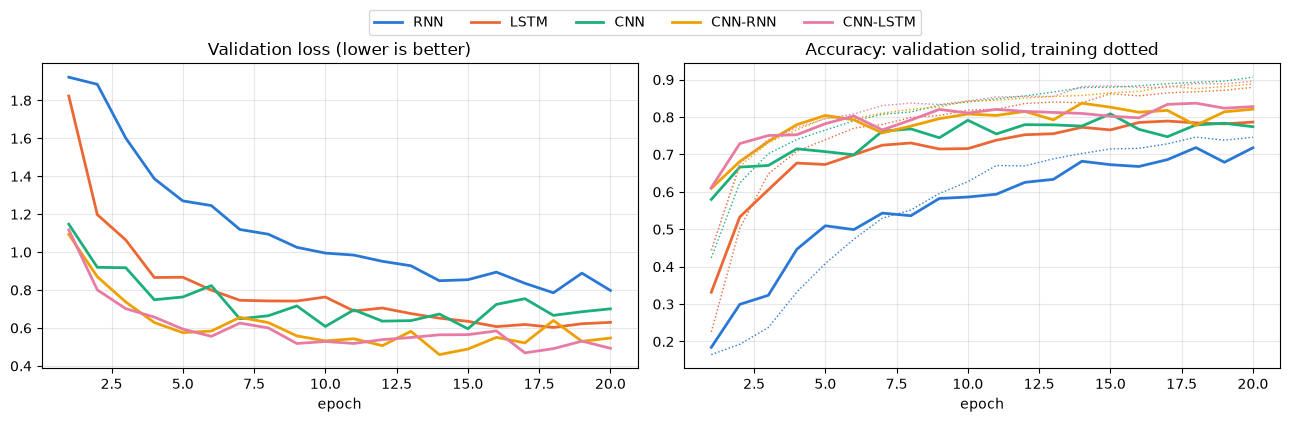

In [ ]:
# ---------------------------------------------------------------------------------------------
# Training curves
#
# What it does:
#     Plot how each model learned over the epochs, using the history of its chosen seed.
#     Left: validation loss. Right: validation accuracy (solid) and training accuracy (dotted).
#
# Steps:
#     1. Give every model one fixed colour, reused in all later charts.
#     2. Make two side-by-side charts.
#     3. For each model: draw validation loss (left), validation and training accuracy (right).
#     4. Add titles, axis labels, grid and one shared legend.
#
# Reading it: a large gap between a model's solid and dotted lines means memorising (overfitting);
# a line still rising at the last epoch means more epochs could help.
# ---------------------------------------------------------------------------------------------

COLOURS = {"RNN": "#2a78d6", "LSTM": "#eb6834",              # 1. one fixed colour per model,
           "CNN": "#1baf7a", "CNN-RNN": "#eda100",           #    used in every chart below
           "CNN-LSTM": "#e87ba4"}

epochs = range(1, EPOCHS + 1)                                # x-axis: epoch 1 .. EPOCHS
fig, ax = plt.subplots(1, 2, figsize=(13, 4))                # 2. left: loss, right: accuracy
for name, history in histories.items():                      # 3. one set of lines per model
    ax[0].plot(epochs, history["val_loss"], color=COLOURS[name], linewidth=2, label=name)        # validation loss
    ax[1].plot(epochs, history["val_acc"], color=COLOURS[name], linewidth=2, label=name)         # validation accuracy (solid)
    ax[1].plot(epochs, history["train_acc"], color=COLOURS[name], linewidth=1, linestyle=":")    # training accuracy (dotted)
ax[0].set_title("Validation loss (lower is better)")         # 4. chart titles
ax[1].set_title("Accuracy: validation solid, training dotted")
for a in ax:                                                 #    same label and grid on both charts
    a.set_xlabel("epoch")
    a.grid(alpha=0.3)
handles, labels = ax[0].get_legend_handles_labels()          #    model names for the legend
fig.legend(handles, labels, loc="upper center", ncol=5, bbox_to_anchor=(0.5, 1.06))   # one shared legend
plt.tight_layout()                                           # fit both charts without overlap
plt.show()

## Step 6: test the models

Each model's best saved weights run once on the unseen test data.

- **Accuracy:** share of windows classified correctly (mean ± std over 3 seeds).
- **Macro F1:** average over gestures, each counted equally; drops if one gesture is often missed.
- **Model time:** time to classify one window, as in live use.
- **Total delay:** window length + model time (target: under 300 ms).

In [ ]:
def predict(model, loader):
    """
    What it does:
        Predict the gesture for every window in a loader. Return the class numbers.

    Steps:
        1. Switch to evaluation mode and turn off gradient tracking.
        2. For each batch: compute scores and keep the highest-scoring gesture.
        3. Join all batches into one array.
    """
    model.eval()                                             # 1. dropout off, batch norm fixed
    predictions = []                                         #    one array of predictions per batch
    with torch.no_grad():                                    #    no gradients: faster, weights unchanged
        for windows, _ in loader:                            # 2. labels not needed here
            predictions.append(model(windows).argmax(dim=1).numpy())   # highest score = predicted gesture
    return np.concatenate(predictions)                       # 3. all batches as one array, in loader order


def time_one_window_ms(model):
    """
    What it does:
        Measure the average time (ms) to classify one window, as in live use.

    Steps:
        1. Take one test window.
        2. Run the model 20 times without timing (warm-up).
        3. Time 200 runs and return the average in milliseconds.
    """
    one_window = torch.tensor(X_test[:1])                    # 1. a single window: [1, time, 8]
    model.eval()                                             #    same mode as live use
    with torch.no_grad():                                    #    no gradients, as in live use
        for _ in range(20):                                  # 2. warm-up runs (first calls are slower)
            model(one_window)
        start = time.perf_counter()                          # 3. precise timer
        for _ in range(200):                                 #    many runs smooth out timing noise
            model(one_window)
    return (time.perf_counter() - start) / 200 * 1000        #    average per run, seconds -> ms

In [ ]:
# ---------------------------------------------------------------------------------------------
# Test every model once
#
# What it does:
#     Load each seed's best saved weights, run them once on the unseen test data, and collect one
#     row of results per model: accuracy and macro F1 (mean over seeds), size, speed and delay.
#
# Steps:
#     1. For each model and each seed: load the best weights and predict the test windows.
#     2. Score accuracy and macro F1 for that seed.
#     3. Keep the chosen seed's model and predictions for the later charts and saving.
#     4. Time one window with the chosen model.
#     5. Store the averages over seeds plus size, speed, delay and training time.
# ---------------------------------------------------------------------------------------------

models = {}                                                  # chosen trained model per name
test_predictions = {}                                        # chosen model's test predictions per name
results = []                                                 # one dict per model -> results table

for name in MODEL_CLASSES:
    accs, f1s = [], []                                       # scores of each seed
    for seed in SEEDS:
        model = build_model(name)                            # 1. empty model of the right shape
        model.load_state_dict(torch.load(f"best_{name}_seed{seed}.pt"))   #    best validation weights of this seed
        preds = predict(model, test_loader)                  #    predicted gesture per test window
        accs.append(accuracy_score(y_test, preds))           # 2. share of windows correct
        f1s.append(f1_score(y_test, preds, average="macro")) #    average F1 over gestures, each counted equally
        if seed == chosen_seed[name]:                        # 3. keep one model per type for the later plots and saving
            models[name] = model
            test_predictions[name] = preds

    model_ms = time_one_window_ms(models[name])              # 4. ms per window, as in live use
    results.append({                                         # 5. one row of the results table
        "model": name,
        "accuracy": np.mean(accs),                           # mean over seeds
        "accuracy std": np.std(accs),                        # spread over seeds
        "macro F1": np.mean(f1s),                            # mean over seeds
        "parameters": sum(p.numel() for p in models[name].parameters()),   # model size
        "model time (ms)": model_ms,
        "total delay (ms)": WINDOW_MS + model_ms,            # window length + model time
        "training time (s)": training_seconds[name],         # average per seed
    })

### Simple baseline

**LDA** (linear discriminant analysis) is a simple, fast classifier that separates gestures with straight-line
boundaries. It is a common reference in sEMG studies.

**Input:** 32 hand-made features per window, 4 for each of the 8 channels:

| Feature | Measures |
|---|---|
| RMS | signal strength |
| MAV | average size |
| WL | how much the signal wiggles |
| ZC | how often it crosses zero |

**Why it is here:** the deep models only justify their extra size and training time if they clearly beat
this baseline. A small gap means the task is mostly solved by simple signal strength.

In [ ]:
def hand_made_features_LDA(windows):
    """
    What it does:
        Compute 4 classic sEMG features per channel for every window (input to the LDA baseline).

    Steps:
        1. RMS: square, average over time, square root (signal strength).
        2. MAV: average absolute value (average size).
        3. WL: sum of absolute changes between neighbouring samples (how much it wiggles).
        4. ZC: number of sign changes (zero crossings).
        5. Join into 32 numbers per window (8 channels x 4 features).
    """
    rms = np.sqrt(np.mean(windows ** 2, axis=1))                     # 1. signal strength       [windows, 8]
    mav = np.mean(np.abs(windows), axis=1)                           # 2. average size          [windows, 8]
    wl = np.sum(np.abs(np.diff(windows, axis=1)), axis=1)            # 3. how much it wiggles   [windows, 8]
    zc = np.sum(np.diff(np.sign(windows), axis=1) != 0, axis=1)      # 4. zero crossings        [windows, 8]
    return np.concatenate([rms, mav, wl, zc], axis=1)                # 5. side by side          [windows, 32]

In [ ]:
# ---------------------------------------------------------------------------------------------
# LDA baseline and results table
#
# What it does:
#     Train a simple linear classifier (LDA) on the 32 hand-made features, add its test scores to
#     the results, and show one formatted table for all models.
#
# Steps:
#     1. Train LDA on the training windows' features; predict the test windows.
#     2. Turn the collected results into a table, one row per model.
#     3. Add the LDA row (accuracy and macro F1 only; the other columns do not apply).
#     4. Display the table with readable number formats ("-" for empty cells).
# ---------------------------------------------------------------------------------------------

lda = LinearDiscriminantAnalysis()                                   # 1. simple linear classifier
lda.fit(hand_made_features_LDA(X_train), y_train)                    #    learn from training features only
lda_predictions = lda.predict(hand_made_features_LDA(X_test))        #    same features for the test windows

results_table = pd.DataFrame(results).set_index("model")             # 2. one row per model
results_table.loc["LDA baseline", "accuracy"] = accuracy_score(y_test, lda_predictions)                 # 3. LDA accuracy
results_table.loc["LDA baseline", "macro F1"] = f1_score(y_test, lda_predictions, average="macro")      #    LDA macro F1

results_table.style.format({                                         # 4. formatted display
    "accuracy": "{:.1%}",                                            #    e.g. 81.0%
    "accuracy std": "{:.1%}",
    "macro F1": "{:.3f}",                                            #    e.g. 0.783
    "parameters": "{:,.0f}",                                         #    e.g. 45,543
    "model time (ms)": "{:.2f}",
    "total delay (ms)": "{:.0f}",
    "training time (s)": "{:.0f}",
}, na_rep="-")                                                       #    "-" where a value does not apply

,accuracy,accuracy std,macro F1,parameters,model time (ms),total delay (ms),training time (s)
model,,,,,,,
RNN,65.8%,5.0%,0.620,"5,191",0.50,151,14
LSTM,76.8%,1.0%,0.743,"19,399",0.74,151,15
CNN,77.9%,0.0%,0.747,"38,151",1.64,152,36
CNN-RNN,80.0%,1.1%,0.774,"20,583",0.93,151,20
CNN-LSTM,81.0%,0.1%,0.783,"45,543",1.19,151,20
LDA baseline,61.9%,-,0.599,-,-,-,-


#### Observation

CNN-LSTM performs best (81%) and RNN worst. CNN-RNN and CNN-LSTM are close; CNN has a lower accuracy std and a
shorter training time. The hybrids and the CNN go forward to tuning.

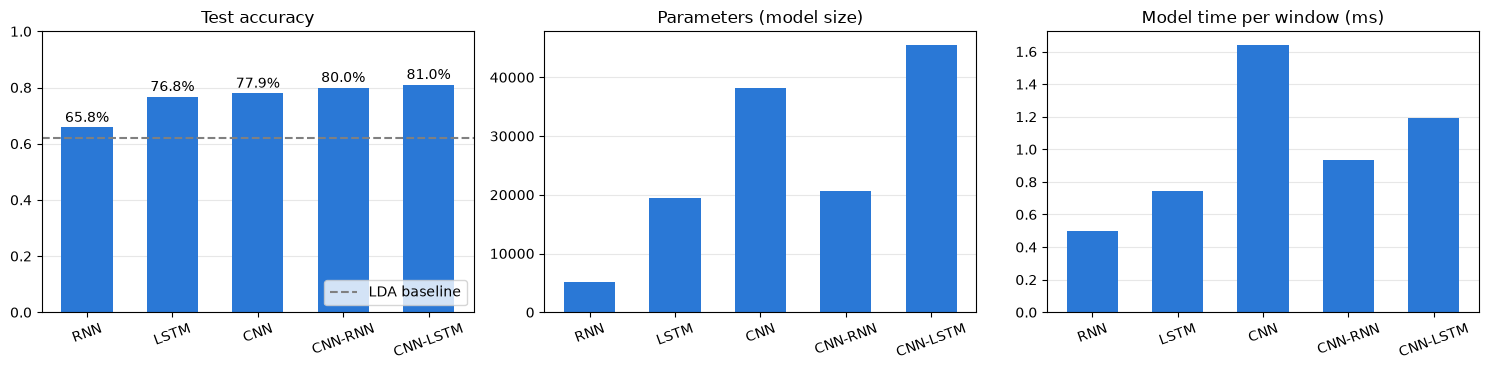

In [ ]:
# ---------------------------------------------------------------------------------------------
# Summary bar charts
#
# What it does:
#     Compare all models side by side on three measures: test accuracy (with the LDA baseline as a
#     dashed line), model size and model time per window.
#
# Steps:
#     1. Make three side-by-side charts.
#     2. Accuracy: one bar per model, dashed LDA line, percentage above each bar.
#     3. Size: number of parameters per model.
#     4. Speed: model time per window.
#     5. Tilt the model names, add a light grid behind the bars.
# ---------------------------------------------------------------------------------------------

fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))              # 1. three charts in one row
names = list(MODEL_CLASSES)                                  #    deep models only (LDA shown as a line)

ax[0].bar(names, results_table.loc[names, "accuracy"], color="#2a78d6", width=0.6)          # 2. test accuracy per model
ax[0].axhline(results_table.loc["LDA baseline", "accuracy"], color="grey", linestyle="--", label="LDA baseline")   #    baseline to beat
ax[0].set_ylim(0, 1); ax[0].set_title("Test accuracy"); ax[0].legend(loc="lower right")     #    0-100% scale, title, legend
for i, value in enumerate(results_table.loc[names, "accuracy"]):                            #    value label above each bar
    ax[0].text(i, value + 0.02, f"{value:.1%}", ha="center")

ax[1].bar(names, results_table.loc[names, "parameters"], color="#2a78d6", width=0.6)        # 3. model size
ax[1].set_title("Parameters (model size)")

ax[2].bar(names, results_table.loc[names, "model time (ms)"], color="#2a78d6", width=0.6)   # 4. speed per window
ax[2].set_title("Model time per window (ms)")

for a in ax:                                                 # 5. same styling on all three charts
    a.tick_params(axis="x", rotation=20)                     #    tilted names so they don't overlap
    a.grid(axis="y", alpha=0.3)                              #    light horizontal grid
    a.set_axisbelow(True)                                    #    grid behind the bars
plt.tight_layout()                                           # fit the charts without overlap
plt.show()

### Confusion matrices

Rows: true gesture. Columns: predicted gesture. Off-diagonal numbers are mix-ups.

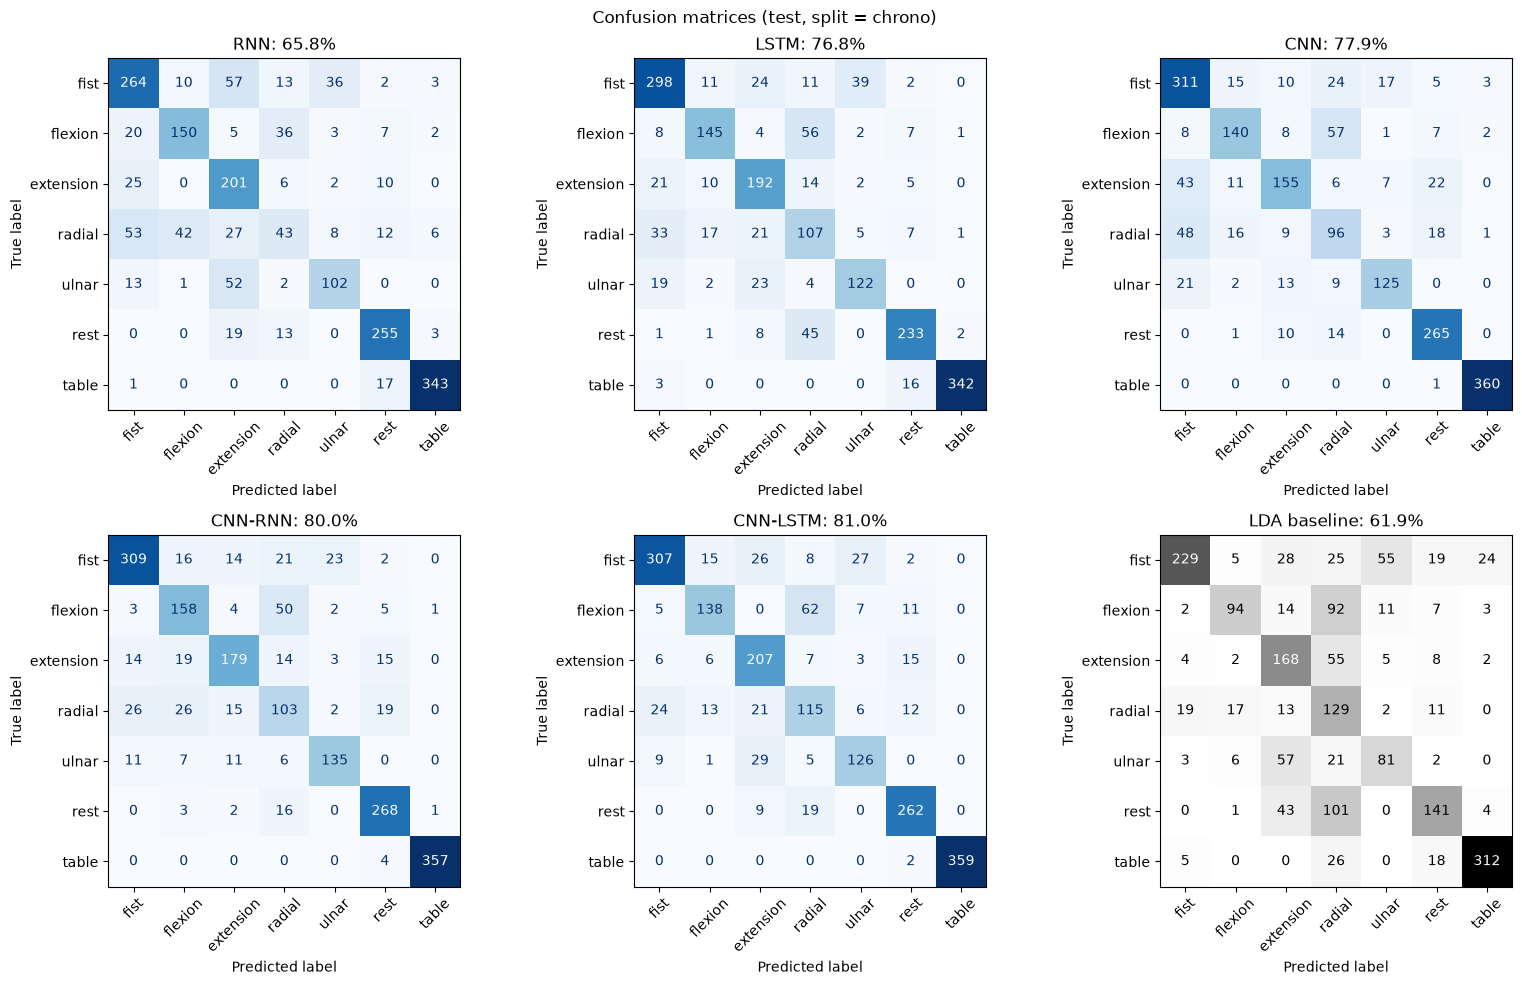

In [ ]:
# ---------------------------------------------------------------------------------------------
# Confusion matrices
#
# What it does:
#     Show, for every model and the LDA baseline, which gestures are predicted correctly and which
#     are mixed up. Rows = true gesture, columns = predicted gesture; the diagonal is correct.
#
# Steps:
#     1. Make a 2 x 3 grid of charts (5 models + LDA).
#     2. One blue matrix per model, titled with its test accuracy.
#     3. A grey matrix for the LDA baseline in the last slot.
#     4. Add an overall title and show.
# ---------------------------------------------------------------------------------------------

fig, axes = plt.subplots(2, 3, figsize=(16, 10))             # 1. 6 slots: 5 models + LDA
axes = axes.flatten()                                        #    2 x 3 grid -> simple list of 6
for i, name in enumerate(MODEL_CLASSES):                     # 2. one matrix per model
    ConfusionMatrixDisplay.from_predictions(y_test, test_predictions[name], display_labels=GESTURE_NAMES,
                                            xticks_rotation=45, cmap="Blues", colorbar=False, ax=axes[i])   # true vs predicted counts
    axes[i].set_title(f"{name}: {results_table.loc[name, 'accuracy']:.1%}")                                 # model name + test accuracy
ConfusionMatrixDisplay.from_predictions(y_test, lda_predictions, display_labels=GESTURE_NAMES,
                                        xticks_rotation=45, cmap="Greys", colorbar=False, ax=axes[5])       # 3. LDA in grey, last slot
axes[5].set_title(f"LDA baseline: {results_table.loc['LDA baseline', 'accuracy']:.1%}")
plt.suptitle(f"Confusion matrices (test, split = {SPLIT_BY})")   # 4. overall title
plt.tight_layout()                                           # fit the charts without overlap
plt.show()

### Accuracy per recording

Each file is one gesture. A recording that every model struggles with points to a data problem
(e.g. a loose band) rather than a model problem.

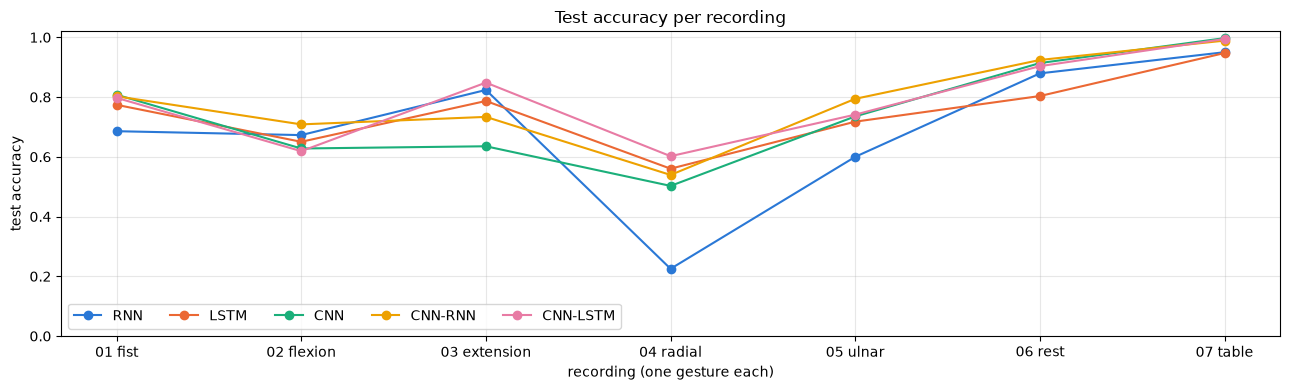

,,RNN,LSTM,CNN,CNN-RNN,CNN-LSTM
recording,gesture,,,,,
01,fist,68.6%,77.4%,80.8%,80.3%,79.7%
02,flexion,67.3%,65.0%,62.8%,70.9%,61.9%
03,extension,82.4%,78.7%,63.5%,73.4%,84.8%
04,radial,22.5%,56.0%,50.3%,53.9%,60.2%
05,ulnar,60.0%,71.8%,73.5%,79.4%,74.1%
06,rest,87.9%,80.3%,91.4%,92.4%,90.3%
07,table,95.0%,94.7%,99.7%,98.9%,99.4%


In [ ]:
# ---------------------------------------------------------------------------------------------
# Accuracy per recording
#
# What it does:
#     Show each model's test accuracy separately for every recording (each recording = one gesture),
#     as a line chart and a colour-coded table. A recording that every model struggles with points
#     to a data problem rather than a model problem.
#
# Steps:
#     1. Make a table: one row per test window, with its recording and gesture.
#     2. Add one column per model: True if that window was predicted correctly.
#     3. Average per recording -> accuracy per recording and model.
#     4. Plot one line per model across the recordings.
#     5. Show the same numbers as a colour-coded table.
# ---------------------------------------------------------------------------------------------

per_file = pd.DataFrame({"recording": test_file,                         # 1. recording of each test window
                         "gesture": np.array(GESTURE_NAMES)[y_test]})   #    each file holds one gesture
for name in MODEL_CLASSES:                                               # 2. True = correct, False = wrong
    per_file[name] = test_predictions[name] == y_test
per_file = per_file.groupby(["recording", "gesture"]).mean()             # 3. share correct per recording

labels = [f"{rec} {gesture}" for rec, gesture in per_file.index]        #    x-axis labels, e.g. "04 radial"

plt.figure(figsize=(13, 4))                                              # 4. one wide chart
for name in MODEL_CLASSES:                                               #    one line per model, same colours as before
    plt.plot(labels, per_file[name], marker="o", markersize=6,
             color=COLOURS[name], linewidth=1.5, label=name)
plt.ylim(0, 1.02); plt.ylabel("test accuracy"); plt.xlabel("recording (one gesture each)")   # 0-100% scale, axis labels
plt.title("Test accuracy per recording")
plt.grid(alpha=0.3); plt.legend(ncol=5, loc="lower left")                #    light grid, legend in one row
plt.tight_layout(); plt.show()

per_file.style.format("{:.1%}").background_gradient(cmap="Blues", vmin=0.3, vmax=1.0)   # 5. table, darker = higher accuracy

### Detailed report for the best model

**Precision:** when the model predicts a gesture, how often it is right. **Recall:** how many of the real
cases of that gesture it finds.

In [ ]:
# ---------------------------------------------------------------------------------------------
# Detailed report for the best model
#
# What it does:
#     Find the model with the highest test accuracy and print its precision, recall and F1 for
#     every gesture, to show which gestures are recognised well and which are weak.
#
# Steps:
#     1. Pick the deep model with the highest test accuracy (LDA excluded via `names`).
#     2. Print its per-gesture report.
# ---------------------------------------------------------------------------------------------

best_name = results_table.loc[names, "accuracy"].idxmax()                # 1. highest test accuracy among the deep models
print(f"Best model on the test set: {best_name}\n")
print(classification_report(y_test, test_predictions[best_name],         # 2. precision, recall, F1 per gesture
                            target_names=GESTURE_NAMES, digits=3))       #    gesture names, 3 decimal places

Best model on the test set: CNN-LSTM

              precision    recall  f1-score   support

        fist      0.875     0.797     0.834       385
     flexion      0.798     0.619     0.697       223
   extension      0.709     0.848     0.772       244
      radial      0.532     0.602     0.565       191
       ulnar      0.746     0.741     0.743       170
        rest      0.862     0.903     0.882       290
       table      1.000     0.994     0.997       361

    accuracy                          0.812      1864
   macro avg      0.789     0.787     0.784      1864
weighted avg      0.819     0.812     0.813      1864



## Step 7: save the models

Each file holds the weights plus the filter, window and normalisation settings needed for live use,
e.g. `CNN-LSTM_semg.pt`.

In [ ]:
# ---------------------------------------------------------------------------------------------
# Save the models
#
# What it does:
#     Save one file per model with the trained weights plus everything needed to prepare live
#     windows exactly as in training (normalisation, filters, window size) and its test scores.
#
# Steps:
#     1. For each model (the chosen seed's version):
#     2. Collect the weights, normalisation, preprocessing settings, window and gesture details,
#        and test scores in one dictionary.
#     3. Save it as "{name}_semg.pt".
# ---------------------------------------------------------------------------------------------

for name, model in models.items():                       # 1. chosen seed's model for each type
    torch.save({                                         # 2. everything in one dictionary
        "model_name": name,                              #    which class to rebuild
        "model_weights": model.state_dict(),             #    trained weights
        "channel_mean": channel_mean.tolist(),           #    normalisation; plain lists, so torch.load works without extra flags
        "channel_std": channel_std.tolist(),
        "preprocessing": PREP,                           #    every pp.preprocess setting (filters, outliers)
        "window_size": WINDOW_SIZE,                      #    samples per window
        "step": STEP,                                    #    samples between windows
        "gestures": GESTURE_NAMES,                       #    class number -> gesture name
        "split": SPLIT_BY,                               #    how the data was split
        "test_accuracy": float(results_table.loc[name, "accuracy"]),    #    mean over seeds
        "test_macro_f1": float(results_table.loc[name, "macro F1"]),    #    mean over seeds
    }, f"{name}_semg.pt")                                # 3. one file per model
    print(f"saved {name}_semg.pt")

saved RNN_semg.pt
saved LSTM_semg.pt
saved CNN_semg.pt
saved CNN-RNN_semg.pt
saved CNN-LSTM_semg.pt


### Ablation: time patterns or just signal strength?

LDA on two reduced inputs: per-channel RMS (strength only, no time order) and a single sample per window.
A large gap between RMS and the best deep model means the models gain from more than signal strength.

In [ ]:
# ---------------------------------------------------------------------------------------------
# Ablation: time patterns or just signal strength?
#
# What it does:
#     Test how much accuracy comes from simple signal strength alone. LDA is trained on two
#     reduced versions of each window and compared with the best deep model and the full LDA.
#
# Steps:
#     1. Define two reductions of a window to 8 numbers:
#        RMS per channel (strength only, time order removed) and the single middle sample.
#     2. For each: train LDA on the reduced training windows, score it on the reduced test windows.
#     3. Print both next to the best deep model and the LDA on 32 hand-made features.
#
# Reading it: a large gap between RMS and the best deep model means the deep models gain from
# more than signal strength.
# ---------------------------------------------------------------------------------------------

rms_of = lambda W: np.sqrt(np.mean(W ** 2, axis=1))          # 1. strength per channel, order removed   [windows, 8]
mid_of = lambda W: W[:, W.shape[1] // 2, :]                   #    one sample from the middle             [windows, 8]

for label, f in (("per-channel RMS (8 numbers, no temporal info)", rms_of),
                 ("one sample per window (8 numbers)", mid_of)):
    lda_small = LinearDiscriminantAnalysis().fit(f(X_train), y_train)        # 2. train on reduced training windows
    score = accuracy_score(y_test, lda_small.predict(f(X_test)))             #    score on reduced test windows
    print(f"LDA on {label:48s} {score:6.1%}")

best = results_table.loc[list(MODEL_CLASSES), "accuracy"].max()              # 3. best deep model's test accuracy
print(f"\nbest deep model{'':40s} {best:6.1%}")
print(f"LDA on 32 hand-made features{'':27s} "                              #    full LDA baseline for comparison
      f"{results_table.loc['LDA baseline', 'accuracy']:6.1%}")

LDA on per-channel RMS (8 numbers, no temporal info)     58.3%
LDA on one sample per window (8 numbers)                 17.5%

best deep model                                          81.0%
LDA on 32 hand-made features                             61.9%
